# Классификация ЭКГ. Вариант 7
## Часть 2. Обучение и сравнение моделей

Цель — построить классификатор для меток `NORM`, `PVC`, `AFIB` и проверить, улучшат ли результат изменение архитектуры, регуляризация и учёт дисбаланса классов. Для каждой записи модель выдаёт три независимые оценки вероятности. Обучение и оценка выполнены на выборке, подготовленной в первой части.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
assert Path("src/ecg_ml").exists(), "Откройте ноутбук из проекта ecg-ml"
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

VARIANT = 7
EXPECTED_CLASSES = ["NORM", "PVC", "AFIB"]
DATASET_PATH = Path(f"data/ptb-xl-variant-{VARIANT}")
BATCH_SIZE = 32
NUM_WORKERS = 0
EPOCHS = 30
SEED = 7
SPLIT_SEED = 0
REUSE_TRAINED = True  # False — обучить обе модели заново.

In [2]:
import json
import logging
import platform
import shutil
import warnings
import zipfile
from dataclasses import asdict, dataclass
from functools import partial

import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ecg_ml.data.warehouse import WarehouseDatasetModule
from ecg_ml.modules.classifier import ClassifierLModule
from IPython.display import Image, display
from IPython.utils.capture import capture_output
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    f1_score,
    multilabel_confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from torch import nn
from torch.utils.data import DataLoader, Dataset

logging.getLogger("lightning.pytorch").setLevel(logging.WARNING)
logging.getLogger("lightning.fabric").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message="Attribute .* is an instance of `nn.Module`.*")
warnings.filterwarnings("ignore", message="The '.*_dataloader' does not have many workers.*")

pd.options.display.float_format = "{:.4f}".format
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {platform.python_version()}, PyTorch {torch.__version__}, Lightning {L.__version__}")
print("Устройство:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Python 3.12.16, PyTorch 2.6.0+cu124, Lightning 2.6.6
Устройство: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Загрузка и разбиение данных

Test берётся из экспорта первой части. Из оставшихся пациентов выделяю 10% для validation (`random_state=0`). Все ЭКГ одного пациента остаются в одной части; проверяю три попарных пересечения.

Сигналы из NPZ один раз распаковываются в `X.npy` рядом с экспортом. Затем `np.load(..., mmap_mode="r")` читает их с диска, а в оперативную память копируется только текущий батч. Такой способ требует дополнительных 4,87 ГиБ на диске, но не загружает весь массив в память. После обновления NPZ файл `X.npy` пересоздаётся.

В `MappedWarehouseDatasetModule` используются группировка пациентов и расчёт весов из `WarehouseDatasetModule`. Нормализация выполняется внутри модели отдельно для каждого отведения каждой ЭКГ.

In [3]:
def load_signals(path):
    archive_path = path / "signals.npz"
    array_path = path / "X.npy"
    if not array_path.exists() or array_path.stat().st_mtime_ns < archive_path.stat().st_mtime_ns:
        temporary = path / "X.partial.npy"
        with zipfile.ZipFile(archive_path) as archive:
            with archive.open("X.npy") as source, temporary.open("wb") as target:
                shutil.copyfileobj(source, target, length=2**20)
        temporary.replace(array_path)
    return np.load(array_path, mmap_mode="r")

In [4]:
class IndexedSignalDataset(Dataset):
    def __init__(self, signals, indices, labels):
        self.signals = signals
        self.indices = indices
        self.labels = labels.astype(np.float32)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        x = np.array(self.signals[self.indices[index]], dtype=np.float32, copy=True)
        return torch.from_numpy(x), torch.from_numpy(self.labels[index])


class MappedWarehouseDatasetModule(WarehouseDatasetModule):
    def __init__(self, path, random_state=0, train_val_ratio=0.1):
        self.path = Path(path)
        with np.load(self.path / "signals.npz") as arrays:
            self.classes = arrays["classes"].tolist()
            y = arrays["y"].astype(np.bool_)
            recording_ids = arrays["recording_id"].astype(str)
            split = arrays["split"].astype(str)
        self.signals = load_signals(self.path)
        if self.signals.dtype != np.float32 or self.signals.shape[1:] != (12, 5000):
            raise ValueError("Ожидаются сигналы float32 формы (N, 12, 5000)")
        if not (len(self.signals) == len(y) == len(recording_ids) == len(split)):
            raise ValueError("Число записей в массивах не совпадает")
        if y.shape != (len(recording_ids), len(self.classes)):
            raise ValueError("Размер меток не совпадает с числом классов")
        if len(set(recording_ids)) != len(recording_ids):
            raise ValueError("Повторяются идентификаторы записей в NPZ")
        meta = pd.read_csv(
            self.path / "meta.csv", dtype={"recording_id": str, "source": str, "patient_id": str}
        )
        if meta["recording_id"].duplicated().any():
            raise ValueError("Повторяются идентификаторы в метаданных")
        meta = meta.set_index("recording_id").loc[recording_ids].reset_index()
        if "split" in meta and not (meta["split"].to_numpy() == split).all():
            raise ValueError("Разбиения в CSV и NPZ не совпадают")
        if set(split) != {"train", "test"}:
            raise ValueError("В экспорте нужны непустые train и test")
        groups = self._patient_groups(meta)
        train_rows, test_rows = np.flatnonzero(split == "train"), np.flatnonzero(split == "test")
        gss = GroupShuffleSplit(n_splits=1, test_size=train_val_ratio, random_state=random_state)
        train_local, val_local = next(gss.split(train_rows, y[train_rows], groups[train_rows]))
        self.indices = {
            "train": train_rows[train_local],
            "val": train_rows[val_local],
            "test": test_rows,
        }
        self.Y_train, self.Y_val, self.Y_test = (
            y[self.indices[part]] for part in ["train", "val", "test"]
        )
        self.metadata = meta.assign(part="")
        group_sets = {part: set(groups[index]) for part, index in self.indices.items()}
        for first, second in [("train", "val"), ("train", "test"), ("val", "test")]:
            if group_sets[first] & group_sets[second]:
                raise ValueError(f"Общие пациенты в {first} и {second}")
        for part, index in self.indices.items():
            self.metadata.loc[index, "part"] = part
            self._log_part(part, y[index], groups[index])

        for begin in range(0, len(self.signals), 128):
            if not np.isfinite(self.signals[begin : begin + 128]).all():
                raise ValueError("В сигналах есть NaN или бесконечные значения")
        self.pos_weight = self._pos_weight(self.Y_train)

    def train_dataset(self):
        return IndexedSignalDataset(self.signals, self.indices["train"], self.Y_train)

    def val_dataset(self):
        return IndexedSignalDataset(self.signals, self.indices["val"], self.Y_val)

    def test_dataset(self):
        return IndexedSignalDataset(self.signals, self.indices["test"], self.Y_test)

In [5]:
dataset = MappedWarehouseDatasetModule(DATASET_PATH, random_state=SPLIT_SEED)
CLASSES = dataset.classes
assert CLASSES == EXPECTED_CLASSES
assert len(dataset.signals) == 21799
summary_rows = []
for part, labels in [("train", dataset.Y_train), ("val", dataset.Y_val), ("test", dataset.Y_test)]:
    meta = dataset.metadata.loc[dataset.indices[part]]
    summary_rows.append(
        {
            "split": part,
            "recordings": len(labels),
            "patients": len(set(dataset._patient_groups(meta))),
            "without_target_labels": int((~labels.any(axis=1)).sum()),
            **dict(zip(CLASSES, labels.sum(axis=0))),
        }
    )
display(pd.DataFrame(summary_rows))
display(pd.DataFrame({"class": CLASSES, "pos_weight_train": dataset.pos_weight}))
print("Общих пациентов между частями нет. Порядок классов:", CLASSES)

,split,recordings,patients,without_target_labels,NORM,PVC,AFIB
0,train,15641,13575,7233,6832,840,1048
1,val,1739,1509,780,771,79,131
2,test,4419,3785,2044,1911,224,335


,class,pos_weight_train
0,NORM,1.2894
1,PVC,17.6202
2,AFIB,13.9246


Общих пациентов между частями нет. Порядок классов: ['NORM', 'PVC', 'AFIB']


## 2. Архитектура классификатора

Вход имеет форму `(batch, 12, 5000)`. Сначала для каждого отведения вычитается его среднее и выполняется деление на стандартное отклонение. Далее используются усреднение по времени, начальная свёртка и три остаточных блока `Conv1d` с BatchNorm и GELU.

После свёрток признаки агрегируются средним и максимумом по времени. Их объединение проходит через dropout и линейный слой с тремя выходами. На выходе возвращаются логиты: sigmoid применяется при расчёте вероятностей. Softmax не используется, поскольку метки не исключают друг друга.

In [6]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=2):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv1d(
                in_channels,
                out_channels,
                kernel_size,
                stride=stride,
                padding=kernel_size // 2,
                bias=False,
            ),
            nn.BatchNorm1d(out_channels),
            nn.GELU(),
            nn.Conv1d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm1d(out_channels),
        )
        self.skip = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, 1, stride=stride, bias=False),
            nn.BatchNorm1d(out_channels),
        )
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(self.main(x) + self.skip(x))


class ECGClassifier(nn.Module):
    def __init__(self, output_size=3, width=16, dropout=0.1):
        super().__init__()
        if output_size < 1 or width < 1:
            raise ValueError("output_size and width must be positive")
        self.stem = nn.Sequential(
            nn.AvgPool1d(5),
            nn.Conv1d(12, width, 15, stride=2, padding=7, bias=False),
            nn.BatchNorm1d(width),
            nn.GELU(),
        )
        self.features = nn.Sequential(
            ResidualBlock(width, width * 2, 9),
            ResidualBlock(width * 2, width * 4, 7),
            ResidualBlock(width * 4, width * 4, 5),
        )
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(width * 8, output_size))

    def forward(self, x):
        if x.ndim != 3 or x.shape[1:] != (12, 5000):
            raise ValueError(f"Expected (batch, 12, 5000), got {tuple(x.shape)}")

        x = x.float()
        x = (x - x.mean(dim=-1, keepdim=True)) / x.std(
            dim=-1, keepdim=True, correction=0
        ).clamp_min(1e-6)
        x = self.features(self.stem(x))
        pooled = torch.cat([x.mean(dim=-1), x.amax(dim=-1)], dim=1)
        return self.head(pooled)

In [7]:
probe = ECGClassifier(output_size=len(CLASSES))
probe.eval()
with torch.inference_mode():
    output = probe(torch.zeros(2, 12, 5000))
assert output.shape == (2, 3) and torch.isfinite(output).all()
print("Размер входа: (2, 12, 5000). Размер выхода:", tuple(output.shape))
print("Число параметров baseline:", sum(p.numel() for p in probe.parameters()))
del probe, output

Размер входа: (2, 12, 5000). Размер выхода: (2, 3)
Число параметров baseline: 77987


## 3. Условия эксперимента

Сравниваются базовая модель и вторая конфигурация с учётом дисбаланса.

| Параметр | Baseline | Improved |
|---|---:|---:|
| Ширина начального слоя | 16 | 24 |
| Dropout | 0,1 | 0,3 |
| Оптимизатор | Adam | AdamW |
| Шаг обучения | 0,001 | 0,0003 |
| Weight decay | 0 | 0,0001 |
| Веса положительного класса в BCE | 1 | число отрицательных / число положительных в train |

В обоих случаях используются `BCEWithLogitsLoss`, batch size 32 и не более 30 эпох. Early stopping останавливает обучение после шести эпох без улучшения validation macro-F1. Планировщик уменьшает шаг вдвое после трёх эпох без улучшения этой метрики. Норма градиента ограничена единицей. Seed обучения равен 7; на GPU применяется смешанная точность.

Checkpoint выбирается по максимуму validation macro-F1. Для перевода вероятностей в метки установлен порог `p > 0.5`. Test не используется для выбора настроек. Во второй конфигурации изменяется сразу несколько параметров, поэтому сравнение показывает их совместный эффект.

При `REUSE_TRAINED = True` загружаются результаты завершённых запусков из `logs/variant7/`. Для нового обучения нужно задать `False`. При повторной оценке сохраняются отдельные журналы; история обучения берётся из исходного запуска.


При изменении параметров эксперимента нужно отключить `REUSE_TRAINED`, чтобы не использовать прежние веса.


In [8]:
@dataclass(frozen=True)
class Experiment:
    name: str
    learning_rate: float = 1e-3
    width: int = 16
    dropout: float = 0.1
    weighted_loss: bool = False
    weight_decay: float = 0.0
    max_epochs: int = EPOCHS
    patience: int = 6


EXPERIMENTS = (
    Experiment("baseline"),
    Experiment(
        "improved", learning_rate=3e-4, width=24, dropout=0.3, weighted_loss=True, weight_decay=1e-4
    ),
)

In [9]:
def fit_experiment(config, completed_run_dir=None):
    L.seed_everything(SEED, workers=True)
    torch.set_num_threads(min(torch.get_num_threads(), 8))
    network = ECGClassifier(output_size=len(CLASSES), width=config.width, dropout=config.dropout)
    weights = (
        torch.tensor(dataset.pos_weight, dtype=torch.float32) if config.weighted_loss else None
    )
    if weights is not None and (not torch.isfinite(weights).all() or (weights <= 0).any()):
        raise ValueError("В train нужны положительные и отрицательные примеры каждого класса")

    optimizer = torch.optim.AdamW if config.weight_decay else torch.optim.Adam
    model = ClassifierLModule(
        network=network,
        criterion=nn.BCEWithLogitsLoss(pos_weight=weights),
        optimizer=partial(optimizer, lr=config.learning_rate, weight_decay=config.weight_decay),
        lr_scheduler={
            "scheduler": partial(
                torch.optim.lr_scheduler.ReduceLROnPlateau, mode="max", factor=0.5, patience=3
            ),
            "monitor": "val/f1/macro",
            "interval": "epoch",
            "frequency": 1,
        },
        labels=CLASSES,
    )
    checkpoint = ModelCheckpoint(
        monitor="val/f1/macro",
        mode="max",
        save_top_k=1,
        save_last=False,
        filename="epoch_{epoch:02d}",
        auto_insert_metric_name=False,
    )
    early_stop = EarlyStopping(
        monitor="val/f1/macro",
        mode="max",
        patience=config.patience,
        min_delta=1e-4,
    )
    log_root = "logs/variant7/evaluation" if completed_run_dir else "logs/variant7"
    logger = CSVLogger(log_root, name=config.name)
    trainer = L.Trainer(
        accelerator="gpu" if torch.cuda.is_available() else "cpu",
        devices=1,
        precision="16-mixed" if torch.cuda.is_available() else "32-true",
        max_epochs=config.max_epochs,
        gradient_clip_val=1.0,
        deterministic=True,
        callbacks=[checkpoint, early_stop] if completed_run_dir is None else [],
        enable_checkpointing=completed_run_dir is None,
        logger=logger,
        enable_progress_bar=False,
        enable_model_summary=False,
        log_every_n_steps=25,
    )
    datamodule = dataset.to_datamodule(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

    if completed_run_dir is None:
        trainer.fit(model=model, datamodule=datamodule)
        chosen_checkpoint = Path(checkpoint.best_model_path)
        metrics_path = Path(logger.log_dir) / "metrics.csv"
    else:
        metrics_path = completed_run_dir / "metrics.csv"
        candidates = list((completed_run_dir / "checkpoints").glob("epoch_*.ckpt"))
        if len(candidates) != 1:
            raise ValueError("В сохранённом запуске должен быть один лучший checkpoint")
        chosen_checkpoint = candidates[0]

    history = pd.read_csv(metrics_path).dropna(subset=["val/f1/macro", "epoch"])
    epochs = int(history["epoch"].max()) + 1
    best_epoch = int(history.loc[history["val/f1/macro"].idxmax(), "epoch"])
    if epochs < config.max_epochs and epochs - 1 - best_epoch < config.patience:
        raise ValueError("Обучение в этом запуске не завершено")
    assert chosen_checkpoint.stem == f"epoch_{best_epoch:02d}"

    # Файлы весов получены при обучении этих моделей в данной работе.
    saved = torch.load(chosen_checkpoint, map_location="cpu", weights_only=False)
    model.load_state_dict(saved["state_dict"])
    del saved
    validation = trainer.validate(
        model=model,
        datamodule=datamodule,
        verbose=False,
    )[0]
    print(
        f"{config.name}: {epochs} эпох, лучшая — {best_epoch + 1}, "
        f"validation macro-F1 = {validation['val/f1/macro']:.4f}"
    )
    return {
        "config": asdict(config),
        "model": model,
        "trainer": trainer,
        "datamodule": datamodule,
        "checkpoint": chosen_checkpoint.as_posix(),
        "validation": validation,
        "epochs": epochs,
        "metrics_csv": str(metrics_path),
        "parameters": sum(p.numel() for p in network.parameters()),
    }

In [10]:
def predict(model, data, batch_size=32):
    loader = DataLoader(data, batch_size=batch_size, shuffle=False, num_workers=0)
    device = next(model.parameters()).device
    model.eval()
    probabilities, targets = [], []
    with torch.inference_mode():
        for x, y in loader:
            probabilities.append(torch.sigmoid(model(x.to(device)).float()).cpu().numpy())
            targets.append(y.numpy())
    return np.concatenate(probabilities), np.concatenate(targets).astype(np.uint8)


def classification_metrics(targets, probabilities, classes):

    labels = (probabilities > 0.5).astype(np.uint8)
    report = classification_report(
        targets, labels, target_names=classes, zero_division=0, output_dict=True
    )
    result = {
        "macro_f1": float(f1_score(targets, labels, average="macro", zero_division=0)),
        "micro_f1": float(f1_score(targets, labels, average="micro", zero_division=0)),
        "report": report,
        "confusion_matrix": multilabel_confusion_matrix(targets, labels).tolist(),
        "average_precision": {},
        "roc_auc": {},
    }
    for index, name in enumerate(classes):
        truth = targets[:, index]
        has_both = len(np.unique(truth)) == 2
        result["roc_auc"][name] = (
            float(roc_auc_score(truth, probabilities[:, index])) if has_both else None
        )
        result["average_precision"][name] = (
            float(average_precision_score(truth, probabilities[:, index])) if truth.any() else None
        )
    return result

In [11]:
def evaluate_experiments(runs, dataset, output_dir="reports/variant7", batch_size=32):

    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    selected = max(runs, key=lambda run: run["validation"]["val/f1/macro"])
    print("По validation выбрана модель:", selected["config"]["name"])
    result = {
        "variant": VARIANT,
        "classes": list(dataset.classes),
        "seed": SEED,
        "split_seed": SPLIT_SEED,
        "threshold": 0.5,
        "selected_by_validation": selected["config"]["name"],
        "selection_metric": "val/f1/macro",
        "dataset": dataset.fingerprint(),
        "pos_weight_train_only": dataset.pos_weight.tolist(),
        "environment": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "lightning": L.__version__,
            "cuda": torch.version.cuda,
            "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
        },
        "experiments": {},
    }
    rows = []
    for run in runs:
        name = run["config"]["name"]

        with capture_output():
            lightning_test = run["trainer"].test(
                model=run["model"],
                datamodule=run["datamodule"],
                verbose=False,
            )[0]
        probabilities, targets = predict(run["model"], dataset.test_dataset(), batch_size)
        metrics = classification_metrics(targets, probabilities, dataset.classes)
        if not np.isclose(metrics["macro_f1"], lightning_test["test/f1/macro"], atol=1e-6):
            raise AssertionError("Значения test macro-F1 в scikit-learn и Lightning не совпадают")
        result["experiments"][name] = {
            "config": run["config"],
            "parameters": run["parameters"],
            "epochs": run["epochs"],
            "checkpoint": run["checkpoint"],
            "validation": run["validation"],
            "test": metrics,
        }
        rows.append(
            {
                "experiment": name,
                "val_macro_f1": run["validation"]["val/f1/macro"],
                "test_macro_f1": metrics["macro_f1"],
                "test_micro_f1": metrics["micro_f1"],
                "parameters": run["parameters"],
                "epochs": run["epochs"],
            }
        )
        np.savez_compressed(
            Path(run["metrics_csv"]).parent / "test_predictions.npz",
            probabilities=probabilities,
            targets=targets,
            classes=np.array(dataset.classes),
        )

        pd.read_csv(run["metrics_csv"]).to_csv(output / f"{name}_history.csv", index=False)
        plot_confusions(
            metrics["confusion_matrix"], dataset.classes, output / f"{name}_confusion.png"
        )

    reference = np.broadcast_to(dataset.Y_train.mean(axis=0), targets.shape)
    result["constant_reference"] = classification_metrics(targets, reference, dataset.classes)
    comparison = pd.DataFrame(rows)
    comparison.to_csv(output / "comparison.csv", index=False)
    (output / "results.json").write_text(
        json.dumps(result, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8"
    )
    plot_learning_curves(runs, output / "learning_curves.png")
    return result, comparison

In [12]:
def plot_confusions(confusions, classes, path):
    fig, axes = plt.subplots(1, len(classes), figsize=(10.5, 3.5), squeeze=False)
    for axis, name, matrix in zip(axes[0], classes, confusions):
        matrix = np.asarray(matrix)
        axis.imshow(matrix, cmap="Blues", vmin=0)
        for (row, col), count in np.ndenumerate(matrix):
            color = "white" if count > matrix.max() / 2 else "#172033"
            axis.text(col, row, str(count), ha="center", va="center", color=color)
        axis.set(
            title=name,
            xlabel="Предсказанная метка",
            ylabel="Истинная метка",
            xticks=[0, 1],
            yticks=[0, 1],
        )
        axis.tick_params(length=0)
    fig.tight_layout()
    fig.savefig(path, dpi=160, facecolor="white")
    plt.close(fig)


def plot_learning_curves(runs, path):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    colors = ["#315c9b", "#c57235"]
    for run, color in zip(runs, colors):
        frame = pd.read_csv(run["metrics_csv"])
        name = run["config"]["name"]
        for axis, metric in zip(axes, ["val/loss", "val/f1/macro"]):
            data = frame.dropna(subset=[metric, "epoch"]).groupby("epoch")[metric].last()
            axis.plot(data.index + 1, data, label=name, color=color, linewidth=1.8)
    for axis, title, ylabel in zip(
        axes, ["Потери на validation", "Macro-F1 на validation"], ["BCE", "Macro-F1"]
    ):
        axis.set(title=title, xlabel="Эпоха", ylabel=ylabel)
        axis.grid(alpha=0.2)
        axis.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(path, dpi=160, facecolor="white")
    plt.close(fig)

In [13]:
completed_baseline = Path("logs/variant7/baseline/version_1")
baseline_run = fit_experiment(
    EXPERIMENTS[0],
    completed_run_dir=completed_baseline if REUSE_TRAINED and completed_baseline.exists() else None,
)

baseline: 17 эпох, лучшая — 11, validation macro-F1 = 0.8734


In [14]:
completed_improved = Path("logs/variant7/improved/version_1")
improved_run = fit_experiment(
    EXPERIMENTS[1],
    completed_run_dir=completed_improved if REUSE_TRAINED and completed_improved.exists() else None,
)

improved: 17 эпох, лучшая — 10, validation macro-F1 = 0.8640


## 4. Результаты на тестовой выборке

После выбора checkpoint по validation рассчитываются precision, recall и F1 для каждого класса, macro-F1, micro-F1, AP и ROC-AUC. В матрицах ошибок строки соответствуют истинной метке, столбцы — предсказанной; порядок элементов: `[[TN, FP], [FN, TP]]`.

По validation выбрана baseline: macro-F1 равен 0,8734 против 0,8640. Ниже приведены итоговые результаты на test для обеих моделей.

Кривые loss показывают ход каждого запуска. Сравнивать их абсолютные значения напрямую нельзя: во второй модели используются веса BCE. Для сравнения моделей служит validation macro-F1.


In [15]:
results, comparison = evaluate_experiments(
    [baseline_run, improved_run], dataset, batch_size=BATCH_SIZE
)
display(comparison)

class_rows = []
for name, run in results["experiments"].items():
    for code in CLASSES:
        metrics = run["test"]["report"][code]
        class_rows.append(
            {
                "Модель": name,
                "Класс": code,
                "Precision": metrics["precision"],
                "Recall": metrics["recall"],
                "F1": metrics["f1-score"],
                "AP": run["test"]["average_precision"][code],
                "ROC-AUC": run["test"]["roc_auc"][code],
                "Поддержка": int(metrics["support"]),
            }
        )
display(pd.DataFrame(class_rows))
print(f"Macro-F1 константного прогноза: {results['constant_reference']['macro_f1']:.4f}")

По validation выбрана модель: baseline


,experiment,val_macro_f1,test_macro_f1,test_micro_f1,parameters,epochs
0,baseline,0.8734,0.8461,0.8585,77987,17
1,improved,0.8640,0.8455,0.8567,172275,17


,Модель,Класс,Precision,Recall,F1,AP,ROC-AUC,Поддержка
0,baseline,NORM,0.8087,0.9267,0.8637,0.9193,0.9471,1911
1,baseline,PVC,0.7800,0.8705,0.8228,0.7979,0.9831,224
2,baseline,AFIB,0.8624,0.8418,0.8520,0.8825,0.9855,335
3,improved,NORM,0.8359,0.8901,0.8621,0.9175,0.9461,1911
4,improved,PVC,0.8274,0.8348,0.8311,0.8155,0.9800,224
5,improved,AFIB,0.7764,0.9224,0.8431,0.8663,0.9816,335


Macro-F1 константного прогноза: 0.0000


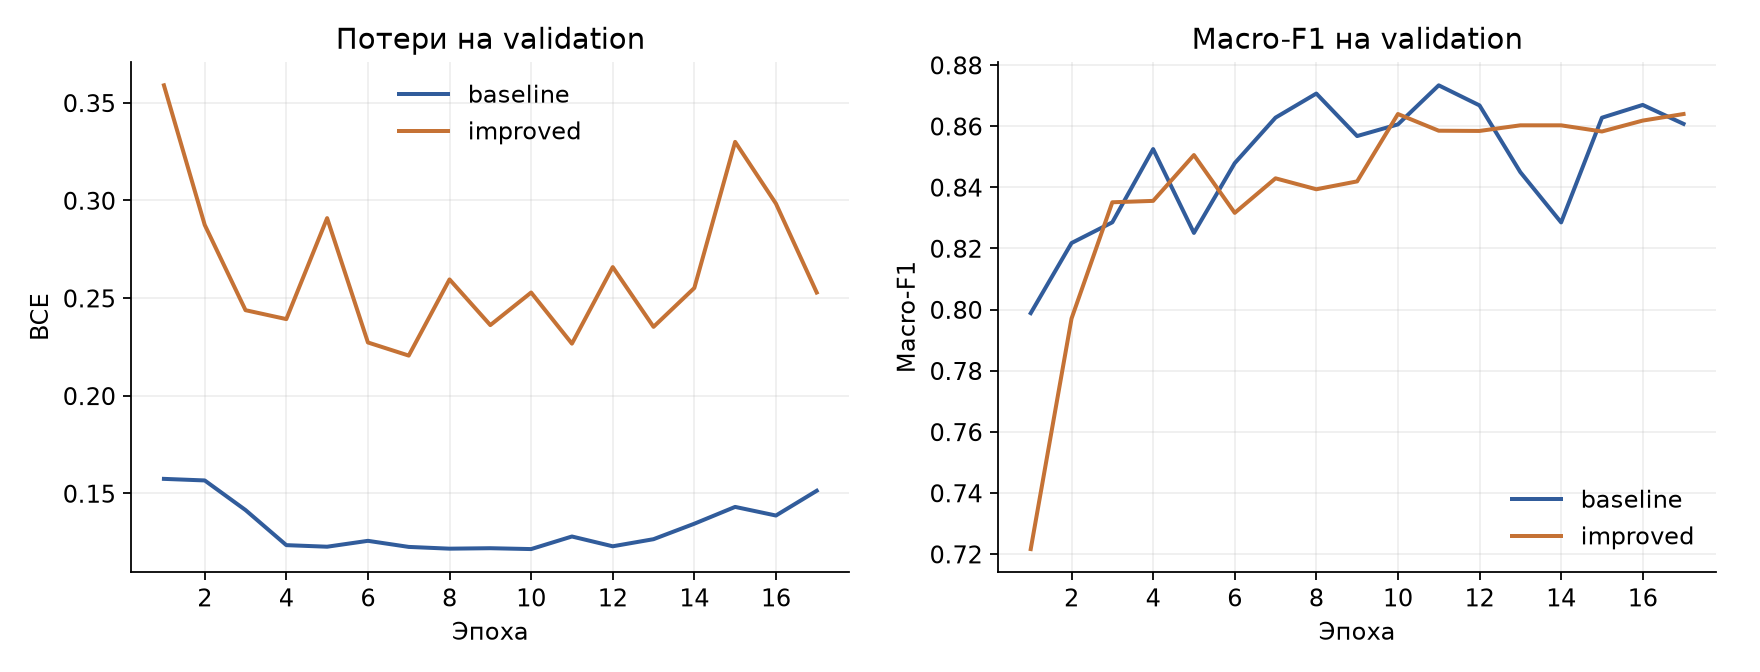

Матрицы ошибок: baseline


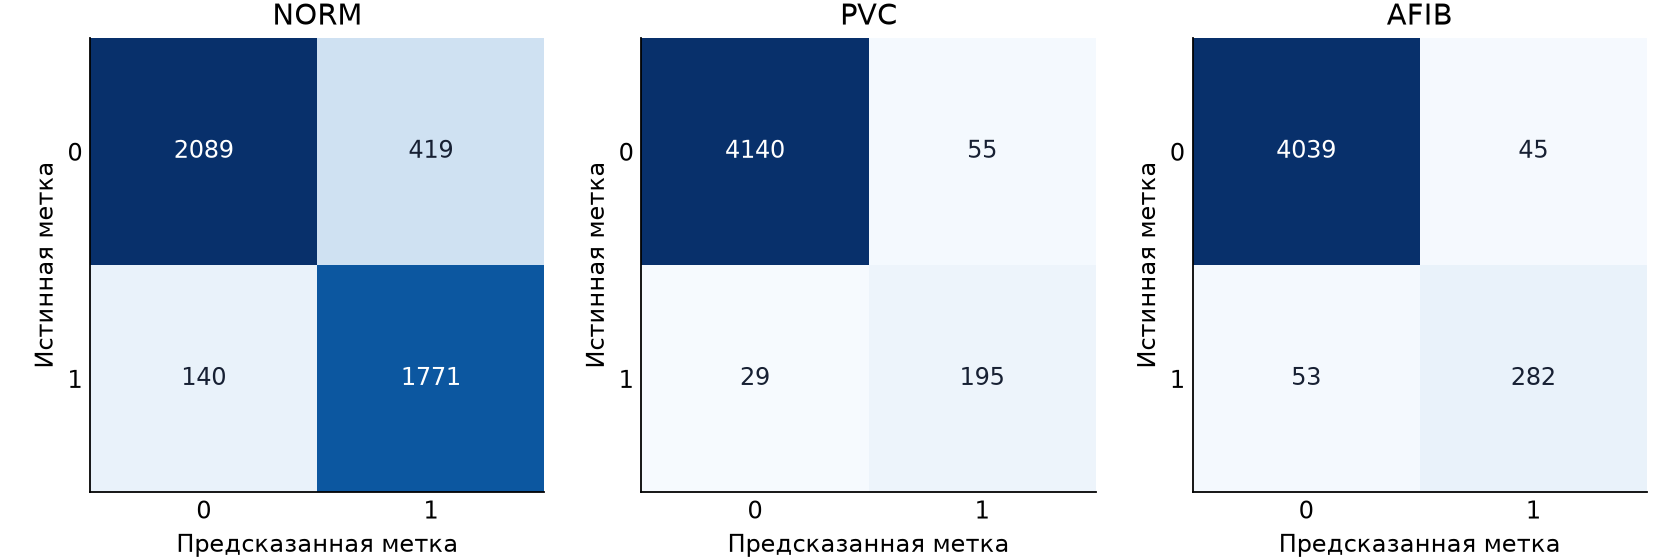

Матрицы ошибок: improved


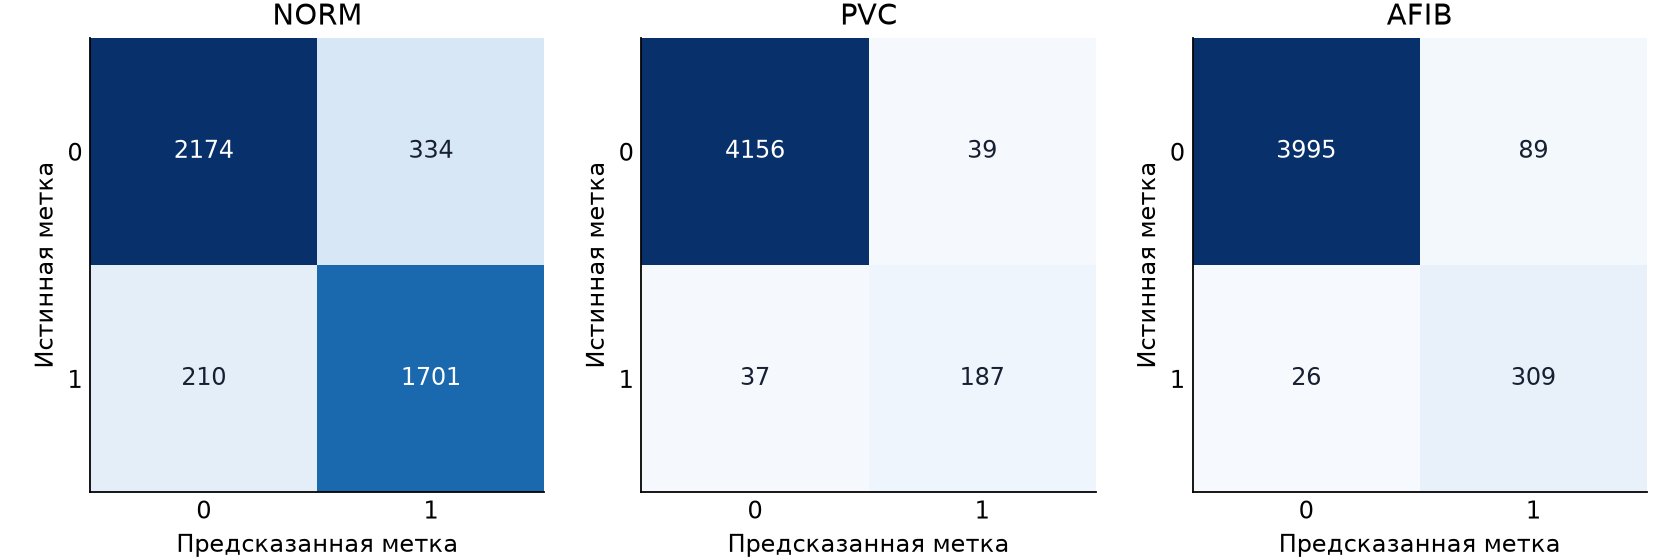

In [16]:
display(Image(filename="reports/variant7/learning_curves.png"))
for name in ["baseline", "improved"]:
    print(f"Матрицы ошибок: {name}")
    display(Image(filename=f"reports/variant7/{name}_confusion.png"))

## 5. Вывод

На тестовой выборке baseline получила macro-F1 **0,8461**, а вторая конфигурация — **0,8455**. Базовая модель выбрана по validation: 0,8734 против 0,8640. Вторая конфигурация не повысила macro-F1 и содержит больше параметров: 172 275 против 77 987.

У второй модели увеличился F1 по PVC: с 0,8228 до 0,8311. Для AFIB вырос recall, но снизился precision: число пропущенных случаев уменьшилось с 53 до 26, а число ложноположительных предсказаний выросло с 45 до 89. Снижение F1 по NORM и AFIB перекрыло прирост по PVC. Отделить вклад весов BCE от остальных изменений по двум запускам нельзя.

Результаты получены для одного разбиения по пациентам и одного seed обучения. Разница test macro-F1 составляет около 0,0007; по такому сравнению нельзя утверждать статистическую значимость различий. Итоговые таблицы и графики сохранены в `reports/variant7/`.